# LSTM Neural Network for Stock Price Prediction

This notebook implements LSTM (Long Short-Term Memory) neural networks using PyTorch for time series prediction of stock prices.

In [1]:
# Import necessary libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import warnings
warnings.filterwarnings('ignore')

# Set device
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")
print(f"PyTorch version: {torch.__version__}")

# Set random seeds for reproducibility
torch.manual_seed(42)
np.random.seed(42)

Using device: cpu
PyTorch version: 2.8.0+cpu


In [2]:
# Load and prepare data (same as linear regression)
import os

data_path = r"e:\Modelling\Project\Data -Working"

def convert_volume(vol_str):
    try:
        vol_str = str(vol_str).strip()
        if vol_str.endswith('M'):
            return float(vol_str[:-1]) * 1_000_000
        elif vol_str.endswith('K'):
            return float(vol_str[:-1]) * 1_000
        else:
            return float(vol_str)
    except:
        return np.nan

def load_stock_data(file_path):
    try:
        df = pd.read_csv(file_path)
        df.columns = df.columns.str.replace('"', '')
        df['Date'] = pd.to_datetime(df['Date'], format='%d-%m-%Y')
        
        numeric_columns = ['Price', 'Open', 'High', 'Low']
        for col in numeric_columns:
            if col in df.columns:
                df[col] = df[col].astype(str).str.replace(',', '').astype(float)
        
        if 'Vol.' in df.columns:
            df['Volume'] = df['Vol.'].astype(str).str.replace(',', '')
            df['Volume'] = df['Volume'].apply(convert_volume)
            df = df.drop('Vol.', axis=1)
        
        if 'Change %' in df.columns:
            df['Change_Pct'] = df['Change %'].astype(str).str.replace('%', '').astype(float)
            df = df.drop('Change %', axis=1)
        
        df = df.sort_values('Date').reset_index(drop=True)
        return df
    except Exception as e:
        print(f"Error loading {file_path}: {str(e)}")
        return None

# Load TCS data
tcs_file = os.path.join(data_path, 'TCS-Historical-Data.csv')
tcs_data = load_stock_data(tcs_file)

print(f"TCS data loaded: {len(tcs_data)} records")
print(f"Columns: {list(tcs_data.columns)}")

TCS data loaded: 2665 records
Columns: ['Date', 'Price', 'Open', 'High', 'Low', 'Volume', 'Change_Pct']


In [3]:
# Prepare data for LSTM
def create_sequences(data, sequence_length):
    """
    Create sequences for LSTM training
    """
    X, y = [], []
    for i in range(sequence_length, len(data)):
        X.append(data[i-sequence_length:i])
        y.append(data[i])
    return np.array(X), np.array(y)

# Use price data for LSTM
price_data = tcs_data['Price'].values.reshape(-1, 1)

# Scale the data
scaler = MinMaxScaler(feature_range=(0, 1))
scaled_data = scaler.fit_transform(price_data)

# Define sequence length (number of previous days to look at)
sequence_length = 60  # 60 days

# Create sequences
X, y = create_sequences(scaled_data, sequence_length)

print(f"Sequence data shape:")
print(f"X shape: {X.shape}")  # (samples, sequence_length, features)
print(f"y shape: {y.shape}")  # (samples, 1)

# Split data (80% train, 20% test)
split_index = int(len(X) * 0.8)

X_train = X[:split_index]
X_test = X[split_index:]
y_train = y[:split_index]
y_test = y[split_index:]

print(f"\nTraining set: {X_train.shape[0]} samples")
print(f"Test set: {X_test.shape[0]} samples")

# Convert to PyTorch tensors
X_train_tensor = torch.FloatTensor(X_train).to(device)
y_train_tensor = torch.FloatTensor(y_train).to(device)
X_test_tensor = torch.FloatTensor(X_test).to(device)
y_test_tensor = torch.FloatTensor(y_test).to(device)

print(f"\nTensor shapes:")
print(f"X_train_tensor: {X_train_tensor.shape}")
print(f"y_train_tensor: {y_train_tensor.shape}")
print(f"Data preparation completed!")

Sequence data shape:
X shape: (2605, 60, 1)
y shape: (2605, 1)

Training set: 2084 samples
Test set: 521 samples

Tensor shapes:
X_train_tensor: torch.Size([2084, 60, 1])
y_train_tensor: torch.Size([2084, 1])
Data preparation completed!


In [4]:
# Define LSTM Model
class LSTMModel(nn.Module):
    def __init__(self, input_size=1, hidden_size=50, num_layers=2, output_size=1, dropout=0.2):
        super(LSTMModel, self).__init__()
        self.hidden_size = hidden_size
        self.num_layers = num_layers
        
        # LSTM layers
        self.lstm = nn.LSTM(input_size, hidden_size, num_layers, 
                           batch_first=True, dropout=dropout)
        
        # Dropout layer
        self.dropout = nn.Dropout(dropout)
        
        # Output layer
        self.linear = nn.Linear(hidden_size, output_size)
        
    def forward(self, x):
        # Initialize hidden state and cell state
        h_0 = torch.zeros(self.num_layers, x.size(0), self.hidden_size).to(device)
        c_0 = torch.zeros(self.num_layers, x.size(0), self.hidden_size).to(device)
        
        # Forward propagate LSTM
        lstm_out, _ = self.lstm(x, (h_0, c_0))
        
        # Get the last time step
        lstm_out = lstm_out[:, -1, :]
        
        # Apply dropout
        lstm_out = self.dropout(lstm_out)
        
        # Get final output
        predictions = self.linear(lstm_out)
        
        return predictions

# Initialize the model
model = LSTMModel(input_size=1, hidden_size=50, num_layers=2, output_size=1, dropout=0.2)
model = model.to(device)

# Define loss function and optimizer
criterion = nn.MSELoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

print("LSTM Model Architecture:")
print(model)
print(f"\nTotal parameters: {sum(p.numel() for p in model.parameters() if p.requires_grad)}")

LSTM Model Architecture:
LSTMModel(
  (lstm): LSTM(1, 50, num_layers=2, batch_first=True, dropout=0.2)
  (dropout): Dropout(p=0.2, inplace=False)
  (linear): Linear(in_features=50, out_features=1, bias=True)
)

Total parameters: 31051


In [5]:
# Training function
def train_model(model, X_train, y_train, X_test, y_test, epochs=100, batch_size=32):
    train_dataset = TensorDataset(X_train, y_train)
    train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
    
    train_losses = []
    test_losses = []
    
    print("Starting training...")
    
    for epoch in range(epochs):
        model.train()
        epoch_train_loss = 0
        
        for batch_X, batch_y in train_loader:
            optimizer.zero_grad()
            outputs = model(batch_X)
            loss = criterion(outputs, batch_y)
            loss.backward()
            optimizer.step()
            epoch_train_loss += loss.item()
        
        # Calculate average training loss
        avg_train_loss = epoch_train_loss / len(train_loader)
        train_losses.append(avg_train_loss)
        
        # Evaluate on test set
        model.eval()
        with torch.no_grad():
            test_outputs = model(X_test)
            test_loss = criterion(test_outputs, y_test).item()
            test_losses.append(test_loss)
        
        # Print progress every 10 epochs
        if (epoch + 1) % 10 == 0:
            print(f'Epoch [{epoch+1}/{epochs}], Train Loss: {avg_train_loss:.6f}, Test Loss: {test_loss:.6f}')\
    
    return train_losses, test_losses

# Train the model
print("Training LSTM model...")
train_losses, test_losses = train_model(model, X_train_tensor, y_train_tensor, 
                                       X_test_tensor, y_test_tensor, epochs=50, batch_size=32)

print("\\nTraining completed!")

Training LSTM model...
Starting training...
Epoch [10/50], Train Loss: 0.001760, Test Loss: 0.001367
Epoch [20/50], Train Loss: 0.001344, Test Loss: 0.001197
Epoch [30/50], Train Loss: 0.001158, Test Loss: 0.002132
Epoch [40/50], Train Loss: 0.000974, Test Loss: 0.003003
Epoch [50/50], Train Loss: 0.000793, Test Loss: 0.000911
\nTraining completed!


In [6]:
# Make predictions
model.eval()
with torch.no_grad():
    train_predictions = model(X_train_tensor)
    test_predictions = model(X_test_tensor)

# Convert back to numpy and original scale
train_predictions_np = train_predictions.cpu().numpy()
test_predictions_np = test_predictions.cpu().numpy()
y_train_np = y_train_tensor.cpu().numpy()
y_test_np = y_test_tensor.cpu().numpy()

# Inverse transform to get actual prices
train_predictions_actual = scaler.inverse_transform(train_predictions_np)
test_predictions_actual = scaler.inverse_transform(test_predictions_np)
y_train_actual = scaler.inverse_transform(y_train_np)
y_test_actual = scaler.inverse_transform(y_test_np)

# Calculate metrics
train_rmse = np.sqrt(mean_squared_error(y_train_actual, train_predictions_actual))
test_rmse = np.sqrt(mean_squared_error(y_test_actual, test_predictions_actual))
train_mae = mean_absolute_error(y_train_actual, train_predictions_actual)
test_mae = mean_absolute_error(y_test_actual, test_predictions_actual)
train_r2 = r2_score(y_train_actual, train_predictions_actual)
test_r2 = r2_score(y_test_actual, test_predictions_actual)

print("=== LSTM MODEL PERFORMANCE ===")
print(f"Training RMSE: {train_rmse:.2f}")
print(f"Test RMSE: {test_rmse:.2f}")
print(f"Training MAE: {train_mae:.2f}")
print(f"Test MAE: {test_mae:.2f}")
print(f"Training R²: {train_r2:.4f}")
print(f"Test R²: {test_r2:.4f}")

# Calculate percentage error
mean_price = y_test_actual.mean()
percentage_error = (test_rmse / mean_price) * 100
print(f"Percentage Error: {percentage_error:.2f}%")

=== LSTM MODEL PERFORMANCE ===
Training RMSE: 53.41
Test RMSE: 106.36
Training MAE: 38.80
Test MAE: 81.58
Training R²: 0.9964
Test R²: 0.9314
Percentage Error: 2.82%


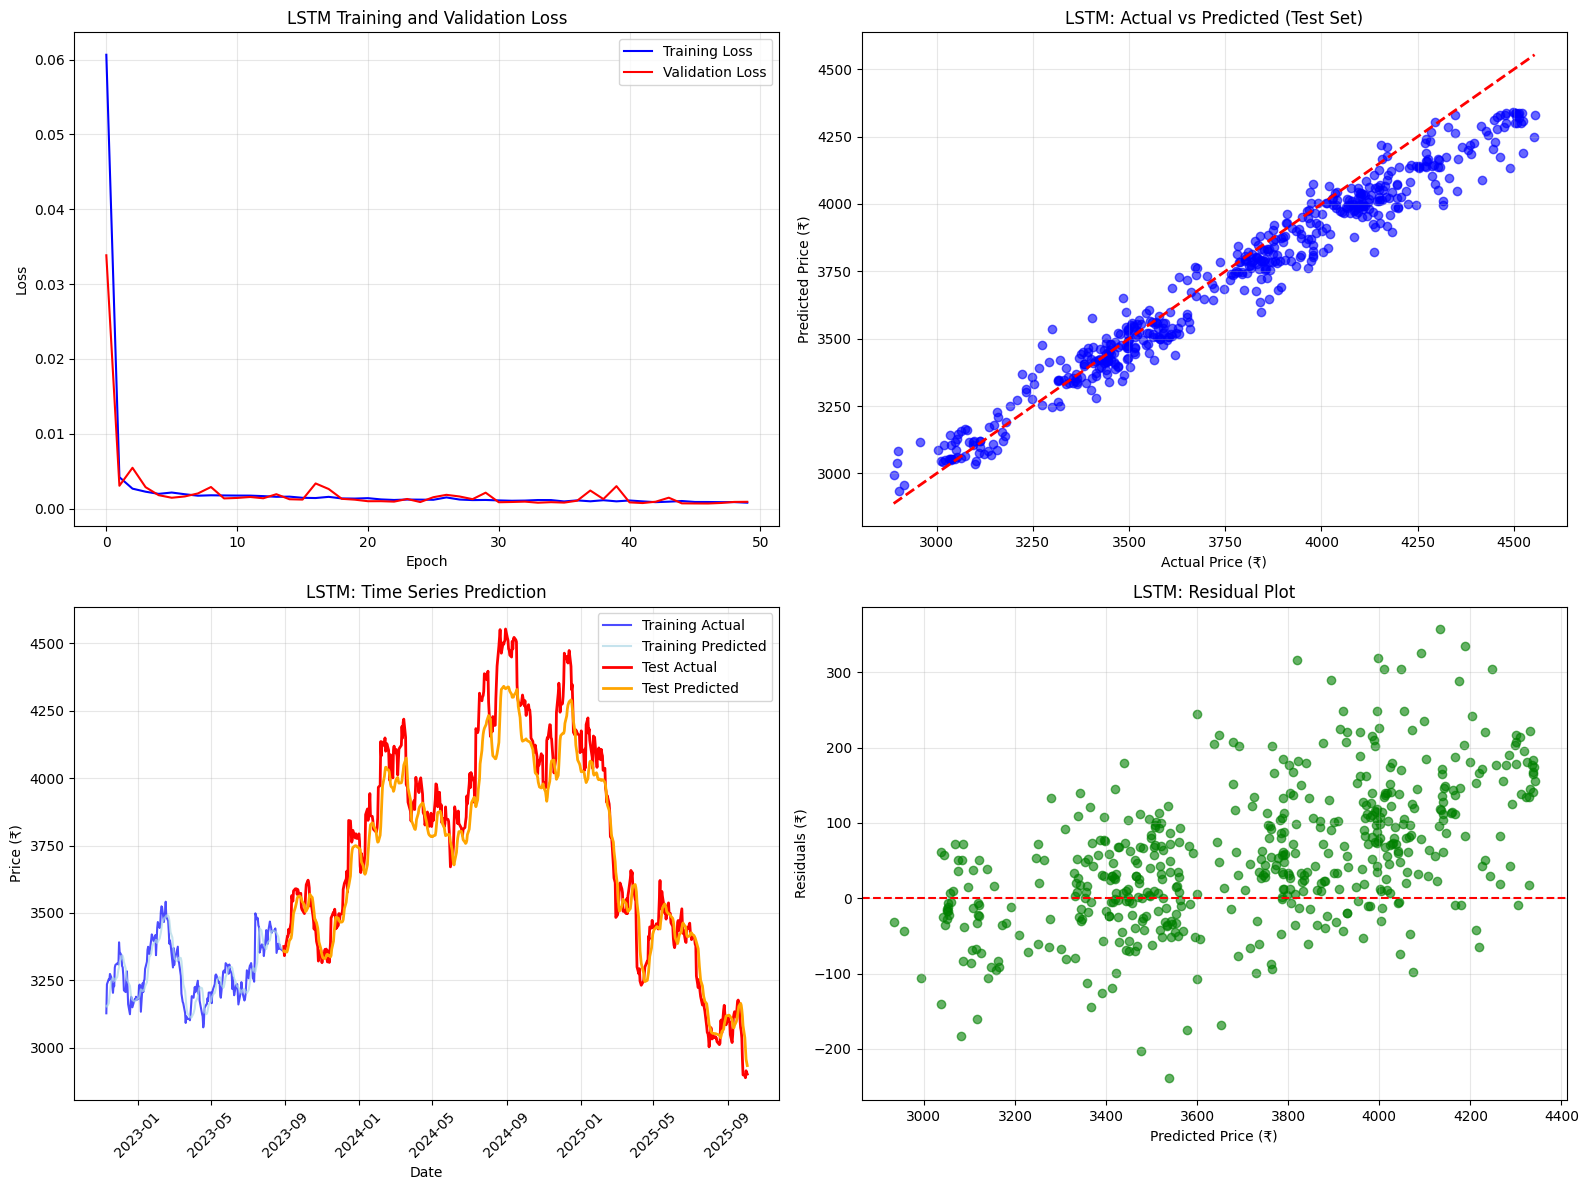

\n=== LSTM MODEL SUMMARY ===
Model Architecture: 2-layer LSTM with 50 hidden units
Sequence Length: 60 days
Training Samples: 2084
Test Samples: 521
Test RMSE: 106.36 ₹
Test R²: 0.9314
Percentage Error: 2.82%


In [7]:
# Create comprehensive visualizations
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# Plot 1: Training and validation loss
ax1 = axes[0, 0]
ax1.plot(train_losses, label='Training Loss', color='blue')
ax1.plot(test_losses, label='Validation Loss', color='red')
ax1.set_xlabel('Epoch')
ax1.set_ylabel('Loss')
ax1.set_title('LSTM Training and Validation Loss')
ax1.legend()
ax1.grid(True, alpha=0.3)

# Plot 2: Actual vs Predicted (Test Set)
ax2 = axes[0, 1]
ax2.scatter(y_test_actual, test_predictions_actual, alpha=0.6, color='blue')
ax2.plot([y_test_actual.min(), y_test_actual.max()], 
         [y_test_actual.min(), y_test_actual.max()], 'r--', lw=2)
ax2.set_xlabel('Actual Price (₹)')
ax2.set_ylabel('Predicted Price (₹)')
ax2.set_title('LSTM: Actual vs Predicted (Test Set)')
ax2.grid(True, alpha=0.3)

# Plot 3: Time Series Prediction
ax3 = axes[1, 0]
# Create date indices for plotting
train_end_idx = len(y_train_actual)
test_start_idx = train_end_idx + sequence_length

# Get corresponding dates
train_dates = tcs_data['Date'][sequence_length:train_end_idx + sequence_length]
test_dates = tcs_data['Date'][test_start_idx:test_start_idx + len(y_test_actual)]

ax3.plot(train_dates.values[-200:], y_train_actual[-200:], 
         label='Training Actual', color='blue', alpha=0.7)
ax3.plot(train_dates.values[-200:], train_predictions_actual[-200:], 
         label='Training Predicted', color='lightblue', alpha=0.7)
ax3.plot(test_dates.values, y_test_actual, 
         label='Test Actual', color='red', linewidth=2)
ax3.plot(test_dates.values, test_predictions_actual, 
         label='Test Predicted', color='orange', linewidth=2)
ax3.set_xlabel('Date')
ax3.set_ylabel('Price (₹)')
ax3.set_title('LSTM: Time Series Prediction')
ax3.legend()
ax3.grid(True, alpha=0.3)
ax3.tick_params(axis='x', rotation=45)

# Plot 4: Residuals
ax4 = axes[1, 1]
residuals = y_test_actual.flatten() - test_predictions_actual.flatten()
ax4.scatter(test_predictions_actual, residuals, alpha=0.6, color='green')
ax4.axhline(y=0, color='red', linestyle='--')
ax4.set_xlabel('Predicted Price (₹)')
ax4.set_ylabel('Residuals (₹)')
ax4.set_title('LSTM: Residual Plot')
ax4.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print("\\n=== LSTM MODEL SUMMARY ===")
print(f"Model Architecture: 2-layer LSTM with 50 hidden units")
print(f"Sequence Length: {sequence_length} days")
print(f"Training Samples: {len(X_train)}")
print(f"Test Samples: {len(X_test)}")
print(f"Test RMSE: {test_rmse:.2f} ₹")
print(f"Test R²: {test_r2:.4f}")
print(f"Percentage Error: {percentage_error:.2f}%")